<a href="https://colab.research.google.com/github/asteriaji/MSSP6070/blob/main/WeeklyModules/Week11/Jiangyu_Ji_PARTICIPATION_ACTIVITY_Week_11_Plotting_geospatial_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import statsmodels.formula.api as sm
import statsmodels.api as se
import seaborn as sns
import datetime as dt
from sklearn.linear_model import LinearRegression
from scipy import stats
from io import StringIO
import itertools
import os
import subprocess
from pathlib import Path

pd.set_eng_float_format(accuracy=3, use_eng_prefix=True)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

owner = 'asteriaji'
repository = 'MSSP6070'
repo_url = f'https://github.com/{owner}/{repository}.git'
repo_path = Path('/content') / repository

if not repo_path.exists():
    subprocess.run(
        ['git', 'clone', repo_url, str(repo_path)],
        check=True
    )
else:
    print("Repository already exists. Using the existing copy.")

os.chdir(repo_path)

print("Current directory:", os.getcwd())

print("Files in repository:")
for item in sorted(repo_path.rglob('*')):
    if item.is_file() and '.git' not in item.parts:
        print(item.relative_to(repo_path))

Current directory: /content/MSSP6070
Files in repository:
Adding_File_Structure.py
Assignment_Template.ipynb
Assignments/.gitkeep
Assignments/Assignment 1/Corrected_Version_Jiangyu_Ji_MSSP_6070_Assignment_1.ipynb
Assignments/Assignment 1/Jiangyu_Ji_MSSP_6070_Assignment_1_260930.ipynb
Assignments/Assignment 2/1
Assignments/Assignment 2/Jiangyu_Ji_Assignment_2.ipynb
WeeklyModules/.gitkeep
WeeklyModules/Week01/.gitkeep
WeeklyModules/Week01/1_introducing_matplotlib_(1).ipynb
WeeklyModules/Week01/Week1_Jiangyu_Ji_Participation_Activity_Exercises_260828.ipynb
WeeklyModules/Week01/stats_viz (1).py
WeeklyModules/Week02/.gitkeep
WeeklyModules/Week02/Week2_Jiangyu_Ji_Participation_Activity_260907__(2).ipynb
WeeklyModules/Week02/Week_2_Data_Stuctures.ipynb
WeeklyModules/Week03/.gitkeep
WeeklyModules/Week03/Week_3_Jiangyu_Ji_PARTICIPATION_ACTIVITY_(3)_(2).ipynb
WeeklyModules/Week04/.gitkeep
WeeklyModules/Week04/Jiangyu_Ji_Assignment_PARTICIPATION_ACTIVITY_Week_4_Opening_a_CSV_file_and_modifying_th

  Name description descriptio  \
0   01        None              
1   02        None              
2   03        None              
3   04        None              
4   05        None              

                                            geometry  
0  MULTIPOLYGON (((-120.07192 41.99495, -120.0010...  
1  MULTIPOLYGON (((-123.69821 41.81719, -123.6967...  
2  MULTIPOLYGON (((-121.667 39.30511, -121.63015 ...  
3  MULTIPOLYGON (((-120.37731 37.61679, -120.3823...  
4  MULTIPOLYGON (((-122.16384 38.64288, -122.1659...  
Number of districts: 53


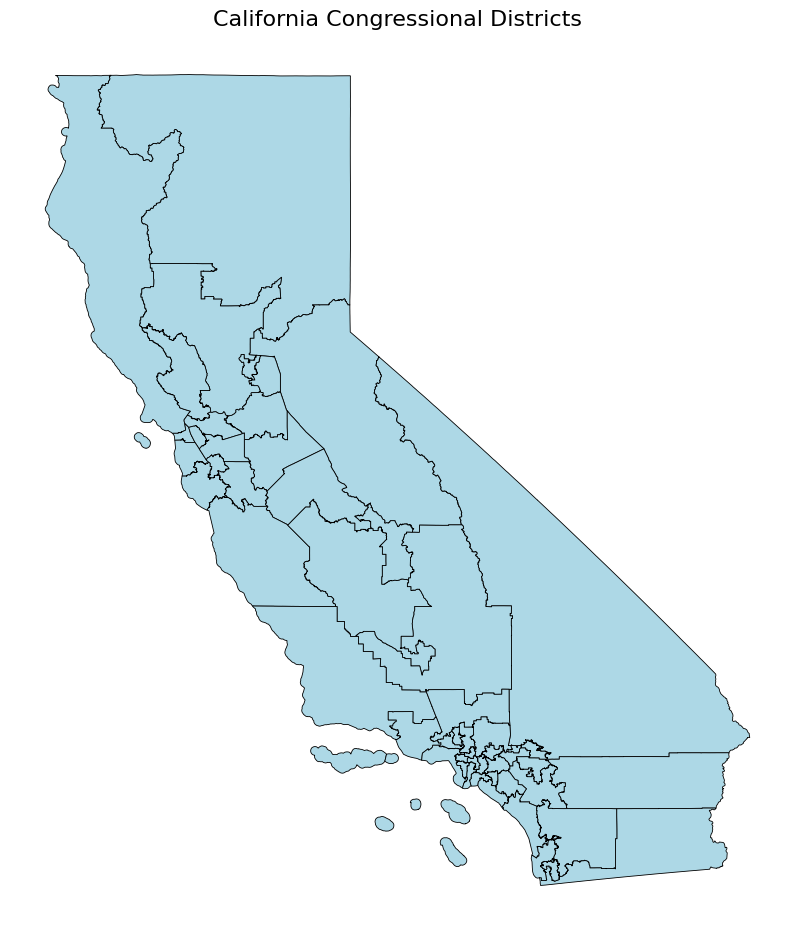

In [2]:
!pip install geopandas matplotlib

import geopandas as gp
import matplotlib.pyplot as plt

ca_districts = gp.read_file(
    "/content/MSSP6070/data/california-congressional-districts.geojson")

print(ca_districts.head())
print("Number of districts:", len(ca_districts))

fig, ax = plt.subplots(figsize=(10, 12))

ca_districts.plot(
    ax=ax,
    edgecolor="black",
    facecolor="lightblue",
    linewidth=0.6)

ax.set_title("California Congressional Districts", fontsize=16)
ax.set_axis_off()

plt.show()

In [3]:
import pandas as pd

legislative = pd.read_csv("/content/MSSP6070/data/CA_Legislative_Districts.csv")

display(legislative.head())

print(legislative.columns.tolist())

print(legislative["DISTRICT"].unique())

print(legislative["POPULATION"].describe())

,OBJECTID,ID,AREA,DISTRICT,MEMBERS,NAME,POPULATION,CVAP_19,HSP_CVAP_1,DOJ_NH_BLK,...,MULTIPLE_F,F_CVAP_19,F_HSP_CVAP,F_DOJ_NH_B,F_DOJ_NH_A,F_NH_WHT_C,DISTRICT_L,DISTRICT_N,SHAPE_Length,SHAPE_Area
0,1,1,27014.63,1,1,MTCAP,760066,549203,77031,10923,...,1|0,0.72,0.14,0.02,0.05,0.75,1|0%,1,2633905.97,122295210592.51
1,2,2,560.65,10,1,STANI,760066,503249,67160,26317,...,10|0,0.66,0.13,0.05,0.17,0.62,10|0%,10,358288.98,2336909010.62
2,3,3,226.43,11,1,COCO,760067,568460,61171,33907,...,11|1,0.75,0.11,0.06,0.32,0.50,11|0%,11,211193.17,940405406.89
3,4,4,141.25,12,1,SF,760065,510978,74038,101894,...,12|-1,0.67,0.14,0.20,0.21,0.42,12|-0%,12,124678.58,586947590.58
4,5,5,6346.92,13,1,OKLND,760065,393416,197645,16042,...,13|-1,0.52,0.50,0.04,0.06,0.37,13|-0%,13,1186867.65,25781145591.73


['OBJECTID', 'ID', 'AREA', 'DISTRICT', 'MEMBERS', 'NAME', 'POPULATION', 'CVAP_19', 'HSP_CVAP_1', 'DOJ_NH_BLK', 'DOJ_NH_ASN', 'NH_WHT_CVA', 'IDEAL_VALU', 'DEVIATION', 'F_DEVIATIO', 'MULTIPLE_F', 'F_CVAP_19', 'F_HSP_CVAP', 'F_DOJ_NH_B', 'F_DOJ_NH_A', 'F_NH_WHT_C', 'DISTRICT_L', 'DISTRICT_N', 'SHAPE_Length', 'SHAPE_Area']
[ 1 10 11 12 13 14 15 16 17 18 19  2 20 21 22 23 24 25 26 27 28 29  3 30
 31 32 33 34 35 36 37 38 39  4 40 41 42 43 44 45 46 47 48 49  5 50 51 52
  6  7  8  9]
count       52.00
mean    760066.10
std          0.77
min     760065.00
25%     760065.75
50%     760066.00
75%     760067.00
max     760067.00
Name: POPULATION, dtype: float64


In [4]:
# GeoJSON shows 53 districts, while the CSV districts document shows only 52 district. So, this
# analysis first checks whether there are 52 common districts between these two.
geo_districts = set(ca_districts["Name"].astype(int))

csv_districts = set(legislative["DISTRICT"].astype(int))

print("GeoJSON districts:", len(geo_districts))
print("CSV districts:", len(csv_districts))

print("Only in GeoJSON:", sorted(geo_districts - csv_districts))
print("Only in CSV:", sorted(csv_districts - geo_districts))
print("Common districts:", len(geo_districts & csv_districts))

GeoJSON districts: 53
CSV districts: 52
Only in GeoJSON: [53]
Only in CSV: []
Common districts: 52


In [5]:
# So, this analysis combines data from the first 52 districts in GeoJSON with data in CSV districts.

ca_districts["DISTRICT"] = ca_districts["Name"].astype(int)
legislative["DISTRICT"] = legislative["DISTRICT"].astype(int)

ca_merged = ca_districts.merge(
    legislative[["DISTRICT", "POPULATION"]],
    on="DISTRICT",
    how="left")

print(ca_merged[["Name", "DISTRICT", "POPULATION"]])
print("Missing population values:", ca_merged["POPULATION"].isna().sum())

   Name  DISTRICT  POPULATION
0    01         1   760066.00
1    02         2   760067.00
2    03         3   760065.00
3    04         4   760065.00
4    05         5   760065.00
5    06         6   760066.00
6    07         7   760066.00
7    08         8   760065.00
8    09         9   760066.00
9    10        10   760066.00
10   11        11   760067.00
11   12        12   760065.00
12   37        37   760066.00
13   13        13   760065.00
14   14        14   760065.00
15   15        15   760066.00
16   16        16   760067.00
17   17        17   760066.00
18   18        18   760065.00
19   19        19   760067.00
20   20        20   760067.00
21   21        21   760065.00
22   22        22   760067.00
23   23        23   760066.00
24   24        24   760066.00
25   25        25   760066.00
26   26        26   760067.00
27   27        27   760067.00
28   28        28   760066.00
29   29        29   760066.00
30   30        30   760066.00
31   31        31   760066.00
32   32   

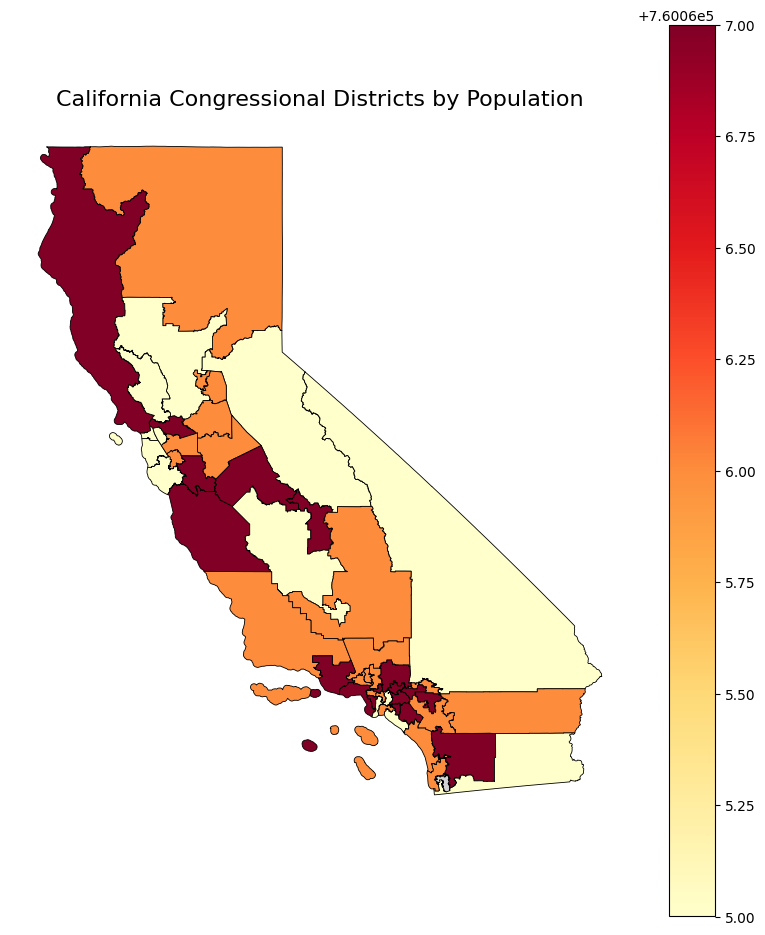

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 12))

ca_merged.plot(
    column="POPULATION",
    cmap="YlOrRd",
    linewidth=0.6,
    edgecolor="black",
    legend=True,
    missing_kwds={
        "color": "lightgrey",
        "label": "No population data"
    },
    ax=ax)

ax.set_title(
    "California Congressional Districts by Population",
    fontsize=16)

ax.set_axis_off()
plt.show()